# DATA 37711 — Homework 3

**How to run:** put this notebook in the same folder as `dset0-1.csv`, `dset1-1.csv` and `winequality-white.csv` (they're all in the repository), install the packages in `requirements.txt`, then choose *Kernel → Restart & Run All*. If `winequality-white.csv` is missing, the notebook downloads it from the UCI repository. A full run takes a few minutes, mostly the random-forest grid search in 2(c).

Random seeds are fixed, so the results are reproducible.

In [1]:
import time, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, accuracy_score, log_loss

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED)
DATA_DIR = Path(".")

---
## Problem 1 — Poisson boosting

Let $Y\in\{0,1,2,\dots\}$, and model $Y\mid X \sim \mathrm{Poi}(\mu(X))$ with $\mu(X)=\exp(f(X))$, $f(X)=\sum_j \lambda_j h_j(X)$, where each $h_j$ is a regression tree.

### (a)
**i. Why Poisson?** $Y$ is a count: a non-negative integer with no fixed upper bound. The Poisson distribution is the standard model for this kind of data. Its support is exactly $\{0,1,2,\dots\}$, so it gives no probability to impossible values such as negative or non-integer $Y$, which a Gaussian would. It also arises naturally as the count of independent rare events, it has one parameter (the mean $\mu$, which is also the variance, so larger means are noisier, as is common with counts), and it is an exponential family, so the negative log-likelihood is a convex, easy-to-optimize loss.

**ii. Why the $\exp$ link?** The Poisson rate must be strictly positive, but a sum of regression trees $f(X)$ can be any real number. $\exp:\mathbb{R}\to(0,\infty)$ maps the unconstrained ensemble output to a valid rate, so boosting can add trees freely without any constraint. In addition:
- $\log$ is the **canonical link** of the Poisson family ($f$ is the natural parameter). This makes the loss convex in $f$ and gives the simple gradient $\mu - Y$ below.
- Effects are multiplicative: adding a tree multiplies the predicted rate by $e^{\lambda_j h_j(X)}$, which suits count data where covariates usually scale the rate.

### (b) Loss
Use the negative log-likelihood. With $P(Y=y\mid X=x)=\frac{e^{y f(x)} e^{-e^{f(x)}}}{y!}$,
$$
L\big(f(x),y\big) = -\log P(Y=y\mid x) = e^{f(x)} - y\,f(x) + \log(y!) .
$$
The $\log(y!)$ term does not depend on $f$ and can be dropped. The empirical risk is $\hat R(f)=\frac1n\sum_{i=1}^n \big(e^{f(x_i)} - y_i f(x_i)\big)$.

### (c) Gradient
$$
\frac{dL}{d f(x)} = e^{f(x)} - y \;=\; \hat\mu(x) - y .
$$
(The second derivative is $e^{f(x)}>0$, so the loss is strictly convex in $f(x)$.)

### (d) Choosing $h_j$ (first-order / gradient boosting)
1. **Initialise** with a constant: $f_0(x)=\log \bar y$, the minimizer of $\sum_i L(c,y_i)$ over constants $c$.
2. For $j=1,\dots,J$:
   - **Pseudo-residuals** (negative gradient at the current fit):
     $r_{i} = -\left.\frac{\partial L}{\partial f(x_i)}\right|_{f=f_{j-1}} = y_i - e^{f_{j-1}(x_i)}$.
   - **Fit the tree** $h_j$ to $\{(x_i, r_i)\}$ by least squares, choosing it from the class of depth-limited regression trees: $h_j=\arg\min_{h}\sum_i (r_i - h(x_i))^2$. This picks the tree that best matches the steepest-descent direction in function space.
   - **Step size** by a 1-D line search on the real loss: $\lambda_j=\arg\min_{\lambda}\sum_i \big(e^{f_{j-1}(x_i)+\lambda h_j(x_i)} - y_i(f_{j-1}(x_i)+\lambda h_j(x_i))\big)$. This problem is convex, and Newton's method solves it in a few steps. In practice we also shrink it by a learning rate $\nu\in(0,1]$ for regularization. (A common refinement re-optimizes each leaf's value separately: for leaf region $R$ the optimum is $\log\frac{\sum_{i\in R} y_i}{\sum_{i\in R} e^{f_{j-1}(x_i)}}$.)
   - **Update** $f_j = f_{j-1} + \nu\lambda_j h_j$.
3. Choose the number of trees $J$, the depth and $\nu$ on held-out data.

---
## Problem 2 — Hyperparameter selection and generalization

### (a) Generalization bound

**Setup.** Using the $n$ training examples we fit one model for each of the $k$ hyperparameter settings, giving $\hat h_1,\dots,\hat h_k$. A test set $S=\{(x_i,y_i)\}_{i=1}^{l}$ is drawn i.i.d. from the data distribution $\mathcal D$, **independently of the training set**. Assume the loss is bounded, $\ell(h(x),y)\in[0,B]$ (for 0-1 loss $B=1$; for squared loss with targets and predictions in $[a,b]$, $B=(b-a)^2$). Define
$$
R(h)=\mathbb E_{(x,y)\sim\mathcal D}\,\ell(h(x),y),\qquad \hat R_S(h)=\frac1l\sum_{i=1}^l \ell(h(x_i),y_i),
$$
and let $\hat\jmath = \arg\min_{j} \hat R_S(\hat h_j)$ be the setting selected on the test set.

**Theorem.** For any $\delta\in(0,1)$, with probability at least $1-\delta$ over the test set,
$$
\big|\hat R_S(\hat h_{\hat\jmath}) - R(\hat h_{\hat\jmath})\big| \;\le\; \max_{1\le j\le k}\big|\hat R_S(\hat h_j) - R(\hat h_j)\big| \;\le\; B\sqrt{\frac{\log(2k/\delta)}{2l}} .
$$
Consequently, on the same event the selected model is also nearly the best of the $k$:
$R(\hat h_{\hat\jmath}) \le \min_j R(\hat h_j) + 2B\sqrt{\log(2k/\delta)/(2l)}$.

**Proof.**
1. *Condition on the training data.* Given the training set, $\hat h_1,\dots,\hat h_k$ are fixed functions, and because the test set is independent of the training set, the test points are still i.i.d. from $\mathcal D$.
2. *Hoeffding for one fixed $j$.* The variables $Z_i^{(j)}=\ell(\hat h_j(x_i),y_i)$, $i=1..l$, are i.i.d., lie in $[0,B]$, and have mean $R(\hat h_j)$. Hoeffding's inequality gives, for every $\epsilon>0$,
   $$\Pr\big(|\hat R_S(\hat h_j) - R(\hat h_j)|>\epsilon\big)\le 2\exp\!\left(-\frac{2l\epsilon^2}{B^2}\right).$$
3. *Union bound over the $k$ models.*
   $$\Pr\Big(\max_j |\hat R_S(\hat h_j)-R(\hat h_j)|>\epsilon\Big)\le \sum_{j=1}^k \Pr\big(|\hat R_S(\hat h_j)-R(\hat h_j)|>\epsilon\big)\le 2k\exp\!\left(-\frac{2l\epsilon^2}{B^2}\right).$$
4. Setting the right-hand side equal to $\delta$ gives $\epsilon = B\sqrt{\log(2k/\delta)/(2l)}$. So with probability $\ge 1-\delta$ the deviation is at most $\epsilon$ *simultaneously* for all $j$.
5. *The selected model.* $\hat\jmath$ depends on $S$, so we cannot apply Hoeffding to $\hat h_{\hat\jmath}$ directly: its test error is not an average of i.i.d. terms with mean $R(\hat h_{\hat\jmath})$. However $\hat\jmath\in\{1,\dots,k\}$ always, so $|\hat R_S(\hat h_{\hat\jmath})-R(\hat h_{\hat\jmath})|\le\max_j|\hat R_S(\hat h_j)-R(\hat h_j)|\le\epsilon$ on the event from step 4.
6. *Near-optimality.* Let $j^*=\arg\min_j R(\hat h_j)$. On the same event,
   $R(\hat h_{\hat\jmath})\le \hat R_S(\hat h_{\hat\jmath})+\epsilon \le \hat R_S(\hat h_{j^*})+\epsilon\le R(\hat h_{j^*})+2\epsilon$. Since this holds for every training set, it also holds unconditionally. $\blacksquare$

**Remarks.** The bound depends on $l$ and $k$ but **not on $n$**. The training-set size affects how good the $k$ candidate models are, but not how well the test set estimates their risks. The price of selecting among $k$ models is only logarithmic, $\sqrt{\log k}$, but it requires $l \gg \log k$.

### (b) Using the same set to select *and* to estimate the error
If the set used to choose $\hat\jmath$ is also used to report the error, the reported number $\hat R_S(\hat h_{\hat\jmath})=\min_j \hat R_S(\hat h_j)$ is a minimum of $k$ noisy estimates. It is **optimistically biased**: $\mathbb E[\min_j \hat R_S(\hat h_j)]\le \min_j R(\hat h_j)$ (the "winner's curse"). The selection step picks whichever model got lucky on these particular $l$ points, so the set has effectively become training data and we are overfitting the test set.

The bound in (a) shows how large the bias can be: it is only controlled at scale $\sqrt{\log k / l}$. When $k$ is large relative to $l$ (e.g. $k\approx e^{l}$, or more simply, when the set of configurations is rich enough to "memorize" the $l$ labels), the bound is vacuous and the reported error can be arbitrarily far below the true error. In the extreme, with $k\ge 2^{l}$ distinct classifiers, one of them can match every test label, giving 0 test error even when every model is a coin flip with true error $0.5$. Choices that depend on the test set (feature selection, early stopping, architecture tweaks) count toward $k$ too.

The simulation below shows this. All $k$ classifiers guess at random (true error exactly $0.5$), but the best test error among them falls well below $0.5$ as $k$ grows, and the drop is larger when $l$ is small.

Reported (min) test error of the selected model; the true error of every model is 0.5


,l=20,l=100,l=500
k (number of configs),,,
1,0.514,0.499,0.500
10,0.324,0.423,0.464
100,0.228,0.376,0.444
1000,0.151,0.338,0.428
10000,0.096,0.307,0.415


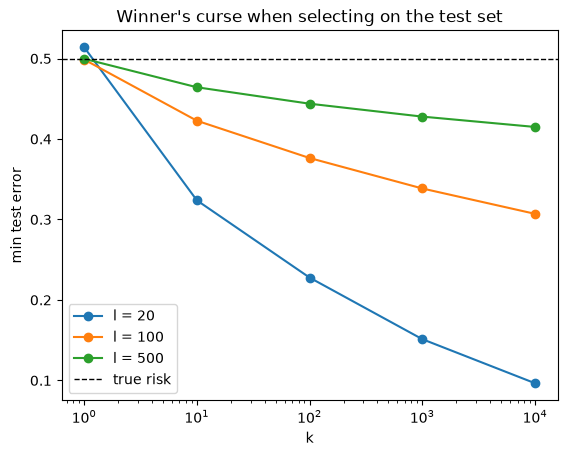

In [2]:
rng = np.random.default_rng(SEED)
ks = [1, 10, 100, 1000, 10000]
ls = [20, 100, 500]
res = {}
for l in ls:
    # test error of each random classifier ~ Binomial(l, 0.5)/l ; report mean over 200 repetitions of min over k
    res[l] = [np.mean([rng.binomial(l, 0.5, size=k).min() / l for _ in range(200)]) for k in ks]
sim = pd.DataFrame(res, index=pd.Index(ks, name="k (number of configs)"))
sim.columns = [f"l={l}" for l in ls]
print("Reported (min) test error of the selected model; the true error of every model is 0.5")
display(sim.round(3))
for l in ls:
    plt.semilogx(ks, sim[f"l={l}"], "o-", label=f"l = {l}")
plt.axhline(0.5, color="k", ls="--", lw=1, label="true risk")
plt.xlabel("k"); plt.ylabel("min test error"); plt.title("Winner's curse when selecting on the test set"); plt.legend(); plt.show()

### (c) Train / validation / test on the white-wine data

We split the data randomly into 70% train, 10% validation and 20% test, and treat `quality` as a regression target with MSE loss. The two model classes are **`RandomForestRegressor`** and **`KNeighborsRegressor`**.

Hyperparameters:
- **Random forest.** `n_estimators` is the number of bootstrapped trees averaged (more trees means lower variance and more compute). `max_depth` and `min_samples_leaf` control how complex each tree is (shallower trees or bigger leaves give more bias and less variance). `max_features` is the fraction of features considered at each split (smaller values decorrelate the trees more).
- **k-NN.** `n_neighbors` is $k$ (small $k$ gives low bias and high variance). `weights` is `uniform`, or `distance` (closer neighbors count more). `p` is the Minkowski exponent of the distance (1 = Manhattan, 2 = Euclidean). k-NN depends on feature scale, so the features are standardized first, with the scaler fit on the training set only, inside a pipeline.

Each grid has **more parameter sets than there are validation points**, as the assignment requires.

*Data note:* this uses the course-provided `winequality-white.csv` (4,898 wines, identical to the UCI white-wine file), which is included in the repository. If the file is missing, the notebook downloads it from UCI.

In [3]:
wine_path = DATA_DIR / "winequality-white.csv"
if not wine_path.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
    pd.read_csv(url, sep=";").to_csv(wine_path, sep=";", index=False)
wine = pd.read_csv(wine_path, sep=None, engine="python")   # handles ';' or ',' separators
wine.columns = [c.strip().strip('"') for c in wine.columns]
print(wine.shape)
display(wine.head())

X_w = wine.drop(columns="quality").values
y_w = wine["quality"].values.astype(float)

# 70 / 10 / 20 split
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_w, y_w, test_size=0.30, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=2/3, random_state=SEED)
print(f"train={len(y_tr)}, validation={len(y_va)}, test={len(y_te)}")
print("Baseline MSE (predict train mean): val = %.4f, test = %.4f" % (
    mean_squared_error(y_va, np.full_like(y_va, y_tr.mean())),
    mean_squared_error(y_te, np.full_like(y_te, y_tr.mean()))))

(4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


train=3428, validation=490, test=980
Baseline MSE (predict train mean): val = 0.8090, test = 0.8149


In [4]:
def grid(d):
    keys = list(d)
    return [dict(zip(keys, v)) for v in itertools.product(*d.values())]

rf_grid = grid({
    "n_estimators":     [50, 100, 200],
    "max_depth":        [None, 5, 10, 15, 20, 30],
    "max_features":     [0.2, 0.33, 0.5, 0.75, 1.0, "sqrt"],
    "min_samples_leaf": [1, 2, 4, 8, 16],
})
knn_grid = grid({
    "n_neighbors": list(range(1, 126)),
    "weights":     ["uniform", "distance"],
    "p":           [1, 2],
})
print(f"#validation points = {len(y_va)}; #RF configs = {len(rf_grid)}; #kNN configs = {len(knn_grid)}")
assert len(rf_grid) > len(y_va) and len(knn_grid) > len(y_va)

def make_model(kind, params):
    if kind == "RandomForest":
        return RandomForestRegressor(random_state=SEED, n_jobs=1, **params)
    return make_pipeline(StandardScaler(), KNeighborsRegressor(**params))

def evaluate(kind, params):
    m = make_model(kind, params).fit(X_tr, y_tr)          # fit on TRAIN only
    return dict(params=params,
                val_mse=mean_squared_error(y_va, m.predict(X_va)),
                test_mse=mean_squared_error(y_te, m.predict(X_te)))  # test MSE kept only for the analysis below; never used to select

results = {}
for kind, g in [("KNeighbors", knn_grid), ("RandomForest", rf_grid)]:
    t0 = time.time()
    results[kind] = pd.DataFrame(Parallel(n_jobs=-1)(delayed(evaluate)(kind, p) for p in g))
    print(f"{kind}: {len(g)} configs in {time.time()-t0:.1f}s")

#validation points = 490; #RF configs = 540; #kNN configs = 500


KNeighbors: 500 configs in 20.4s


RandomForest: 540 configs in 109.5s


In [5]:
summary = []
for kind, df in results.items():
    best = df.loc[df.val_mse.idxmin()]                      # selection uses VALIDATION score only
    summary.append(dict(model=kind, best_params=best.params,
                        best_val_mse=best.val_mse, test_mse_of_selected=best.test_mse,
                        optimism=best.test_mse - best.val_mse,
                        best_possible_test_mse=df.test_mse.min(),
                        corr_val_test=np.corrcoef(df.val_mse, df.test_mse)[0, 1]))
summary = pd.DataFrame(summary).set_index("model")
pd.set_option("display.max_colwidth", 200)
display(summary.round(4))

,best_params,best_val_mse,test_mse_of_selected,optimism,best_possible_test_mse,corr_val_test
model,,,,,,
KNeighbors,"{'n_neighbors': 16, 'weights': 'distance', 'p': 1}",0.4000,0.4615,0.0614,0.4510,0.9865
RandomForest,"{'n_estimators': 200, 'max_depth': 20, 'max_features': 0.2, 'min_samples_leaf': 1}",0.3761,0.4433,0.0671,0.4433,0.9954


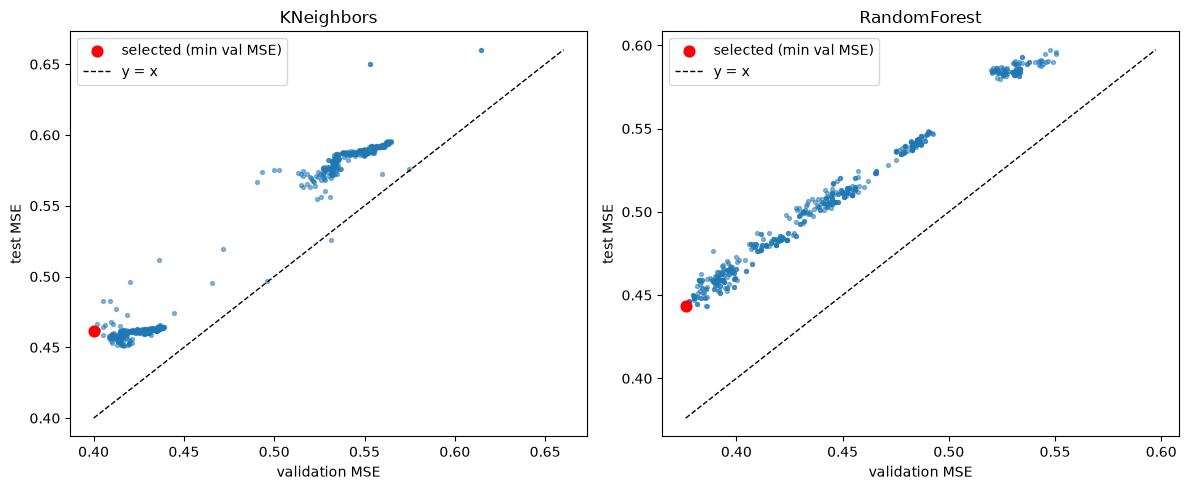

KNeighbors: top-20-by-validation mean val MSE = 0.4074, their mean test MSE = 0.4618
RandomForest: top-20-by-validation mean val MSE = 0.3799, their mean test MSE = 0.4481


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (kind, df) in zip(axes, results.items()):
    ax.scatter(df.val_mse, df.test_mse, s=8, alpha=0.5)
    b = df.loc[df.val_mse.idxmin()]
    ax.scatter([b.val_mse], [b.test_mse], color="red", s=60, label="selected (min val MSE)")
    lo, hi = min(df.val_mse.min(), df.test_mse.min()), max(df.val_mse.max(), df.test_mse.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
    ax.set_xlabel("validation MSE"); ax.set_ylabel("test MSE"); ax.set_title(kind); ax.legend()
plt.tight_layout(); plt.show()

# How optimistic is the validation score of the top-ranked configurations?
for kind, df in results.items():
    top = df.nsmallest(20, "val_mse")
    print(f"{kind}: top-20-by-validation mean val MSE = {top.val_mse.mean():.4f}, "
          f"their mean test MSE = {top.test_mse.mean():.4f}")

**Results and relationship between validation and test risk.** (The numbers are in the tables above.)

- **Test performance.** The selected random forest gets a test MSE of about 0.44 and the selected k-NN about 0.46. Both are far better than the predict-the-mean baseline (about 0.81), and the random forest is a little better.
- **Validation vs. test.** Across all configurations the validation and test MSEs are very strongly correlated (`corr_val_test` ≈ 0.99). The validation set ranks the hyperparameters about the same way the test set does, so it is a useful selection tool.
- **The validation score of the *selected* model is biased downward.** We picked the configuration with the minimum of hundreds of noisy validation estimates, which is the winner's curse from (b). The selected configuration's validation MSE is an optimistic estimate of its true risk, and its test MSE is higher by about 0.06–0.07 for both model classes (`optimism` > 0). Part of this gap is just a validation split that happened to be easy, which is why it is about the same size for both models, and part is the selection effect. The top-20 comparison shows the same thing: configurations ranked best on validation do systematically worse on fresh data. The gap is the selection effect from (a)/(b) at work, since we chose among $k>l$ configurations with only $l\approx 490$ validation points.
- **The test score is the honest estimate.** It was not used for any decision, so by the $k=1$ case of the bound in (a) it is an unbiased estimate of the selected model's risk, with error $O(1/\sqrt{l_{test}})$. This is why we keep the validation set (for selection) separate from the test set (for reporting). Note also that the selected configuration is at or very close to the configuration with the lowest test MSE (`best_possible_test_mse`): for the random forest they coincide, and for k-NN the gap is about 0.01. This is what part (a)'s near-optimality guarantee predicts.

---
## Problem 3 — Generalization of boosting as trees are added

In both files the first column is a binary label (0/1) and the remaining 5 columns are covariates, so we use `GradientBoostingClassifier` with the default settings: log-loss, learning rate 0.1, depth-3 trees. Each dataset is split into 70% train and 30% test (stratified), and we fit models with 1, 10, 100, 300 and 1000 trees, reporting train and test accuracy and log-loss.

One split of 500 points is noisy, so we also repeat the experiment over 10 random splits and plot the average test curves, using `staged_predict_proba` on a single 1000-tree model per split; with `subsample=1.0` this is identical to refitting with fewer trees.

In [7]:
N_TREES = [1, 10, 100, 300, 1000]

def load(name):
    d = pd.read_csv(DATA_DIR / name, header=None)
    return d.iloc[:, 1:].values, d.iloc[:, 0].astype(int).values

def boosting_table(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
    rows = []
    for n in N_TREES:
        m = GradientBoostingClassifier(n_estimators=n, random_state=SEED).fit(Xtr, ytr)
        ptr, pte = m.predict_proba(Xtr)[:, 1], m.predict_proba(Xte)[:, 1]
        rows.append(dict(n_trees=n,
                         train_acc=accuracy_score(ytr, ptr > .5), test_acc=accuracy_score(yte, pte > .5),
                         train_logloss=log_loss(ytr, ptr), test_logloss=log_loss(yte, pte)))
    return pd.DataFrame(rows).set_index("n_trees")

def boosting_curves(X, y, n_splits=10, n_max=1000):
    acc_tr, acc_te, ll_te = [], [], []
    for tr, te in StratifiedShuffleSplit(n_splits, test_size=0.3, random_state=SEED).split(X, y):
        m = GradientBoostingClassifier(n_estimators=n_max, random_state=SEED).fit(X[tr], y[tr])
        acc_tr.append([accuracy_score(y[tr], p[:, 1] > .5) for p in m.staged_predict_proba(X[tr])])
        st = list(m.staged_predict_proba(X[te]))
        acc_te.append([accuracy_score(y[te], p[:, 1] > .5) for p in st])
        ll_te.append([log_loss(y[te], p[:, 1]) for p in st])
    return np.mean(acc_tr, 0), np.mean(acc_te, 0), np.mean(ll_te, 0)

def plot_curves(name, curves):
    acc_tr, acc_te, ll_te = curves
    n = np.arange(1, len(acc_tr) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].semilogx(n, acc_tr, label="train"); ax[0].semilogx(n, acc_te, label="test")
    ax[0].set_xlabel("number of trees"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].set_title(f"{name}: accuracy (avg of 10 splits)")
    ax[1].semilogx(n, ll_te, color="C1"); ax[1].set_xlabel("number of trees"); ax[1].set_ylabel("test log-loss")
    ax[1].set_title(f"{name}: test log-loss"); plt.tight_layout(); plt.show()
    print("Avg test accuracy at", {k: round(acc_te[k-1], 3) for k in N_TREES},
          "| best at n =", int(np.argmax(acc_te)) + 1, f"({acc_te.max():.3f})")

X0, y0 = load("dset0-1.csv")
X1, y1 = load("dset1-1.csv")
print("dset0:", X0.shape, "fraction of 1s = %.3f" % y0.mean(), "| dset1:", X1.shape, "fraction of 1s = %.3f" % y1.mean())

dset0: (500, 5) fraction of 1s = 0.426 | dset1: (500, 5) fraction of 1s = 0.454


### (a) dset0

,train_acc,test_acc,train_logloss,test_logloss
n_trees,,,,
1,0.574,0.573,0.656,0.672
10,0.829,0.680,0.502,0.588
100,0.994,0.833,0.141,0.439
300,1.000,0.840,0.023,0.519
1000,1.000,0.833,0.000,1.013


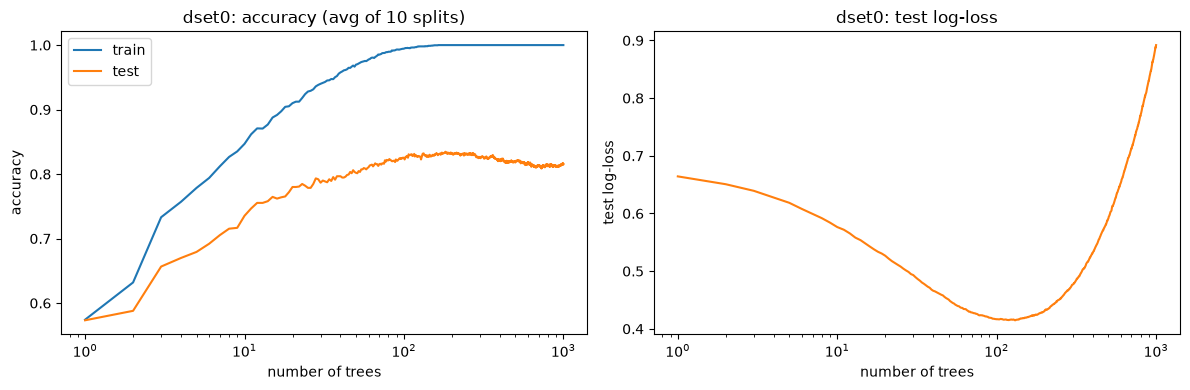

Avg test accuracy at {1: np.float64(0.573), 10: np.float64(0.735), 100: np.float64(0.825), 300: np.float64(0.826), 1000: np.float64(0.815)} | best at n = 182 (0.835)


In [8]:
display(boosting_table(X0, y0).round(3))
curves0 = boosting_curves(X0, y0)
plot_curves("dset0", curves0)

**Observations (dset0).** With 1 tree the model underfits badly (about 57% test accuracy, near the majority-class rate). Test accuracy then rises steadily and keeps improving up to about 100–300 trees (about 83%; the averaged curve peaks near 180 trees). After that it **plateaus and barely degrades**, even though by around 300 trees the training accuracy is 100% and the training loss keeps shrinking. This is the "boosting is surprisingly resistant to overfitting" behaviour discussed in class: adding trees after the training data is fit mostly increases the margins, and the 0-1 test error stays roughly flat. (The test *log-loss* does go up at 1000 trees, because the model becomes over-confident on its few mistakes, but the classification decisions hardly change.)

### (b) dset1

,train_acc,test_acc,train_logloss,test_logloss
n_trees,,,,
1,0.546,0.547,0.639,0.640
10,0.883,0.827,0.408,0.455
100,0.994,0.840,0.108,0.396
300,1.000,0.820,0.021,0.539
1000,1.000,0.827,0.000,1.150


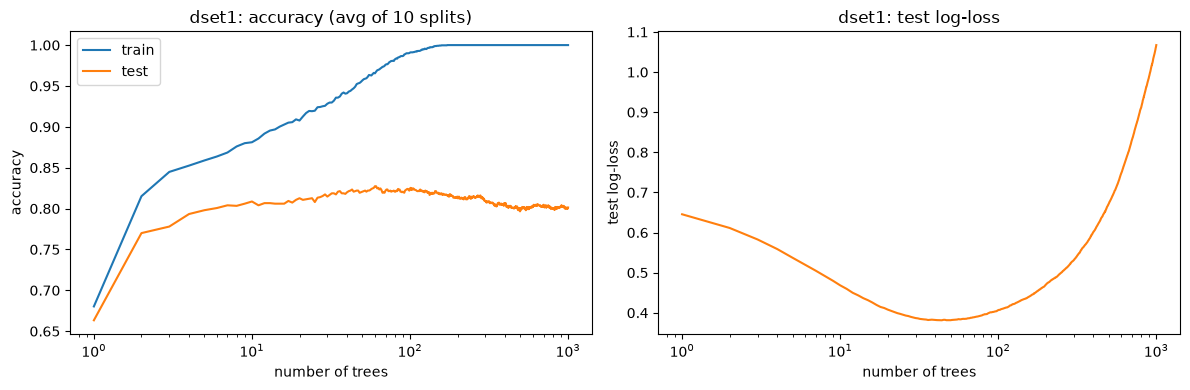

Avg test accuracy at {1: np.float64(0.663), 10: np.float64(0.809), 100: np.float64(0.825), 300: np.float64(0.809), 1000: np.float64(0.801)} | best at n = 60 (0.827)


In [9]:
display(boosting_table(X1, y1).round(3))
curves1 = boosting_curves(X1, y1)
plot_curves("dset1", curves1)

**Observations (dset1).** Here the model is already good with very few trees: about 10 trees reach roughly 81% average test accuracy, versus about 74% for dset0 at the same point. Test accuracy peaks early (around 60 trees in the averaged curve), and then **declines** as more trees are added (to about 80% at 1000 trees in the averaged curve), while training accuracy goes to 100%. The test log-loss rises sharply after its minimum. So on dset1 we see classic overfitting: the extra trees fit noise in the training labels rather than signal, and early stopping or a small number of trees is clearly preferable.

### (c) What property of the data explains the difference?

The two datasets have almost the same marginal distributions and about the same best attainable accuracy (around 83%), so both contain a similar amount of label noise. What differs is **how complex the true decision boundary is relative to that noise.** The diagnostics below compare (i) the linear correlation of each feature with the label, (ii) the feature importances from boosting, and (iii) a plain logistic regression against boosting.

In [10]:
rows = []
for name, (X, y) in {"dset0": (X0, y0), "dset1": (X1, y1)}.items():
    lr_acc, gb_acc = [], []
    for tr, te in StratifiedShuffleSplit(10, test_size=0.3, random_state=SEED).split(X, y):
        lr_acc.append(make_pipeline(StandardScaler(), LogisticRegression()).fit(X[tr], y[tr]).score(X[te], y[te]))
        gb_acc.append(GradientBoostingClassifier(n_estimators=100, random_state=SEED).fit(X[tr], y[tr]).score(X[te], y[te]))
    imp = GradientBoostingClassifier(n_estimators=100, random_state=SEED).fit(X, y).feature_importances_
    rows.append(dict(dataset=name,
                     corr_with_label=np.round([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])], 2),
                     gb_feature_importance=np.round(imp, 2),
                     logistic_test_acc=np.mean(lr_acc), boosting100_test_acc=np.mean(gb_acc)))
display(pd.DataFrame(rows).set_index("dataset").round(3))

,corr_with_label,gb_feature_importance,logistic_test_acc,boosting100_test_acc
dataset,,,,
dset0,"[0.03, 0.2, -0.11, 0.13, -0.16]","[0.47, 0.16, 0.19, 0.11, 0.07]",0.640,0.825
dset1,"[-0.59, -0.29, -0.11, -0.03, 0.2]","[0.55, 0.22, 0.07, 0.06, 0.09]",0.833,0.825


**Interpretation.**

- **dset1 has a simple, nearly linear signal.** Its labels are strongly linearly correlated with the first features, and plain logistic regression does as well as, or better than, boosting. Most of the signal is captured by the first few (dozen) trees. After that the only thing left to fit in the training set is **label noise**: roughly 15–20% of the points sit on the "wrong" side of the boundary and cannot be predicted from $X$. Gradient boosting's log-loss puts ever-increasing weight on these hard, misclassified points, so later trees carve out small regions around noisy labels. The test accuracy goes down.

- **dset0 has a complex, nonlinear signal** (interactions or non-monotone effects). The most important feature for boosting has nearly zero *linear* correlation with the label, and logistic regression is far worse than boosting. The structure has to be built up from many trees, so the extra trees keep adding real signal over a long range (about 100–300). By the time the model interpolates the training set, the additional trees are mostly enlarging margins on a well-founded boundary rather than chasing noise, so the test error stays flat.

In short, boosting's test error stays stable as trees are added when the signal is rich relative to the label noise (dset0). When the signal is simple and the labels are noisy (dset1), the extra capacity goes into fitting the noise, which is the regime where boosting overfits and early stopping matters.